Transformer-Based 28-Day Demand **Forecasting**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import libraries

In [ ]:
import os
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D,
    Add
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Step 11 libraries loaded successfully.")

TensorFlow version: 2.20.0
Step 11 libraries loaded successfully.


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SEQUENCE_DIR = os.path.join(
    PROCESSED_DIR,
    "sequences"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

TRANSFORMER_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "transformer"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

for folder in [
    TRANSFORMER_MODEL_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("Step 11 directories ready.")

Step 11 directories ready.


Check Step 10 sequence files

In [ ]:
TRAIN_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    "train_sequences.npz"
)

VAL_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    "validation_sequences.npz"
)

TEST_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    "test_sequences.npz"
)

required_files = [
    TRAIN_SEQUENCE_PATH,
    VAL_SEQUENCE_PATH,
    TEST_SEQUENCE_PATH
]

all_exist = True

for path in required_files:

    if os.path.exists(path):
        print("FOUND   ->", path)

    else:
        print("MISSING ->", path)
        all_exist = False

if not all_exist:

    raise FileNotFoundError(
        "Step 10 temporal sequence files are missing. "
        "Run Step 10 first."
    )

print("\nAll Step 10 sequence files found.")

FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/sequences/train_sequences.npz
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/sequences/validation_sequences.npz
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/sequences/test_sequences.npz

All Step 10 sequence files found.


Load temporal sequences

In [ ]:
train_data = np.load(
    TRAIN_SEQUENCE_PATH
)

val_data = np.load(
    VAL_SEQUENCE_PATH
)

test_data = np.load(
    TEST_SEQUENCE_PATH
)

X_train = train_data["X"].astype(
    np.float32
)

y_train = train_data["y"].astype(
    np.float32
)

X_val = val_data["X"].astype(
    np.float32
)

y_val = val_data["y"].astype(
    np.float32
)

X_test = test_data["X"].astype(
    np.float32
)

y_test = test_data["y"].astype(
    np.float32
)

print("=" * 70)
print("STEP 11 TEMPORAL DATA")
print("=" * 70)

print(
    "Train      :",
    X_train.shape,
    "->",
    y_train.shape
)

print(
    "Validation :",
    X_val.shape,
    "->",
    y_val.shape
)

print(
    "Test       :",
    X_test.shape,
    "->",
    y_test.shape
)

STEP 11 TEMPORAL DATA
Train      : (79200, 28, 1) -> (79200, 28)
Validation : (300, 28, 1) -> (300, 28)
Test       : (300, 28, 1) -> (300, 28)


Define Transformer dimensions

In [ ]:
SEQUENCE_LENGTH = X_train.shape[1]

INPUT_FEATURES = X_train.shape[2]

HORIZON = y_train.shape[1]

D_MODEL = 32

NUM_HEADS = 4

FF_DIM = 64

NUM_TRANSFORMER_BLOCKS = 2

DROPOUT_RATE = 0.10

print("Sequence length :", SEQUENCE_LENGTH)
print("Input features  :", INPUT_FEATURES)
print("Forecast horizon:", HORIZON)

print("\nTransformer settings")

print("D_MODEL         :", D_MODEL)
print("Attention heads :", NUM_HEADS)
print("FF dimension    :", FF_DIM)
print("Encoder blocks  :", NUM_TRANSFORMER_BLOCKS)

Sequence length : 28
Input features  : 1
Forecast horizon: 28

Transformer settings
D_MODEL         : 32
Attention heads : 4
FF dimension    : 64
Encoder blocks  : 2


Verify data quality

In [ ]:
print(
    "X_train finite:",
    np.isfinite(
        X_train
    ).all()
)

print(
    "X_val finite:",
    np.isfinite(
        X_val
    ).all()
)

print(
    "X_test finite:",
    np.isfinite(
        X_test
    ).all()
)

print(
    "y_train finite:",
    np.isfinite(
        y_train
    ).all()
)

print(
    "y_val finite:",
    np.isfinite(
        y_val
    ).all()
)

print(
    "y_test finite:",
    np.isfinite(
        y_test
    ).all()
)

X_train finite: True
X_val finite: True
X_test finite: True
y_train finite: True
y_val finite: True
y_test finite: True


Create positional encoding layer

In [ ]:
class PositionalEmbedding(tf.keras.layers.Layer):

    def __init__(
        self,
        sequence_length,
        d_model,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.d_model = d_model

        self.position_embedding = (
            tf.keras.layers.Embedding(
                input_dim=sequence_length,
                output_dim=d_model
            )
        )

    def call(
        self,
        inputs
    ):

        length = tf.shape(inputs)[1]

        positions = tf.range(
            start=0,
            limit=length,
            delta=1
        )

        position_vectors = (
            self.position_embedding(
                positions
            )
        )

        return (
            inputs +
            position_vectors
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "sequence_length":
                self.sequence_length,

            "d_model":
                self.d_model
        })

        return config

In [ ]:
dummy_input = tf.zeros(
    (
        2,
        SEQUENCE_LENGTH,
        D_MODEL
    )
)

pos_layer = PositionalEmbedding(
    SEQUENCE_LENGTH,
    D_MODEL
)

dummy_output = pos_layer(
    dummy_input
)

print(
    "Positional encoding output:",
    dummy_output.shape
)

Positional encoding output: (2, 28, 32)


Define Transformer encoder block

In [ ]:
def transformer_encoder(
    inputs,
    d_model,
    num_heads,
    ff_dim,
    dropout_rate=0.1
):

    # -----------------------
    # Self-attention
    # -----------------------

    x = LayerNormalization(
        epsilon=1e-6
    )(inputs)

    attention_output = MultiHeadAttention(

        num_heads=num_heads,

        key_dim=(
            d_model //
            num_heads
        ),

        dropout=dropout_rate

    )(
        x,
        x
    )

    attention_output = Dropout(
        dropout_rate
    )(
        attention_output
    )

    x = Add()([
        inputs,
        attention_output
    ])

    # -----------------------
    # Feed-forward network
    # -----------------------

    y = LayerNormalization(
        epsilon=1e-6
    )(x)

    y = Dense(
        ff_dim,
        activation="relu"
    )(y)

    y = Dropout(
        dropout_rate
    )(y)

    y = Dense(
        d_model
    )(y)

    y = Dropout(
        dropout_rate
    )(y)

    output = Add()([
        x,
        y
    ])

    return output

Build Transformer forecasting model

In [ ]:
tf.keras.backend.clear_session()

transformer_input = Input(
    shape=(
        SEQUENCE_LENGTH,
        INPUT_FEATURES
    ),
    name="Transformer_Input"
)

# --------------------------------
# Project input to D_MODEL
# --------------------------------

x = Dense(
    D_MODEL,
    activation="linear",
    name="Input_Projection"
)(
    transformer_input
)

# --------------------------------
# Positional information
# --------------------------------

x = PositionalEmbedding(
    sequence_length=SEQUENCE_LENGTH,
    d_model=D_MODEL,
    name="Positional_Embedding"
)(x)

# --------------------------------
# Transformer blocks
# --------------------------------

for block_number in range(
    NUM_TRANSFORMER_BLOCKS
):

    x = transformer_encoder(

        inputs=x,

        d_model=D_MODEL,

        num_heads=NUM_HEADS,

        ff_dim=FF_DIM,

        dropout_rate=DROPOUT_RATE
    )

# --------------------------------
# Final normalization
# --------------------------------

x = LayerNormalization(
    epsilon=1e-6,
    name="Final_Normalization"
)(x)

# --------------------------------
# Pool temporal representation
# --------------------------------

x = GlobalAveragePooling1D(
    name="Temporal_Pooling"
)(x)

# --------------------------------
# Forecasting head
# --------------------------------

x = Dense(
    64,
    activation="relu",
    name="Forecast_Dense_64"
)(x)

x = Dropout(
    0.20,
    name="Forecast_Dropout"
)(x)

x = Dense(
    32,
    activation="relu",
    name="Forecast_Dense_32"
)(x)

transformer_output = Dense(
    HORIZON,
    activation="linear",
    name="Forecast_Output"
)(x)

transformer_model = Model(

    inputs=transformer_input,

    outputs=transformer_output,

    name="Transformer_28Day_Forecaster"
)

transformer_model.summary()

Model: "Transformer_28Day_Forecaster"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Transformer_Input   │ (None, 28, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Input_Projection    │ (None, 28, 32)    │         64 │ Transformer_Inpu… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Positional_Embeddi… │ (None, 28, 32)    │        896 │ Input_Projection… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 28, 32)    │         64 │ Positional_Embed… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 28, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 28, 32)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 28, 32)    │          0 │ Positional_Embed… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 28, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 28, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 28, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 28, 32)    │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 28, 32)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 28, 32)    │          0 │ add[0][0],        │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 28, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 28, 32)    │      4,224 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 28, 32)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 28, 32)    │          0 │ add_1[0][0],      │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 28, 32)    │         64 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 28, 64)    │      2,112 │ layer_normalizat

 Total params: 23,228 (90.73 KB)

 Trainable params: 23,228 (90.73 KB)

 Non-trainable params: 0 (0.00 B)

Compile Transformer

In [ ]:
transformer_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mae",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

print(
    "Transformer compiled successfully."
)

Transformer compiled successfully.


Define callbacks

In [ ]:
BEST_TRANSFORMER_PATH = os.path.join(
    TRANSFORMER_MODEL_DIR,
    "best_transformer.keras"
)

transformer_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)

transformer_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)

transformer_checkpoint = ModelCheckpoint(

    filepath=BEST_TRANSFORMER_PATH,

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)

print(
    "Transformer callbacks ready."
)

Transformer callbacks ready.


Train Transformer

In [ ]:
history_transformer = (
    transformer_model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=100,

        batch_size=256,

        shuffle=True,

        callbacks=[
            transformer_early_stop,
            transformer_reduce_lr,
            transformer_checkpoint
        ],

        verbose=1
    )
)

Epoch 1/100
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - loss: 0.7695 - mae: 0.7695
Epoch 1: val_loss improved from None to 0.84535, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/transformer/best_transformer.keras

Epoch 1: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/transformer/best_transformer.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 80s 230ms/step - loss: 0.7018 - mae: 0.7018 - val_loss: 0.8453 - val_mae: 0.8453 - learning_rate: 0.0010
Epoch 2/100
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - loss: 0.6544 - mae: 0.6544
Epoch 2: val_loss improved from 0.84535 to 0.83475, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/transformer/best_transformer.keras

Epoch 2: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/transformer/best_transformer.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 71s 230ms/step - loss: 0.6576 - mae: 0.6576 - val_loss: 0.8347 - val_mae: 0.8347 - learning_rate: 0.0010
E

Plot Transformer training history

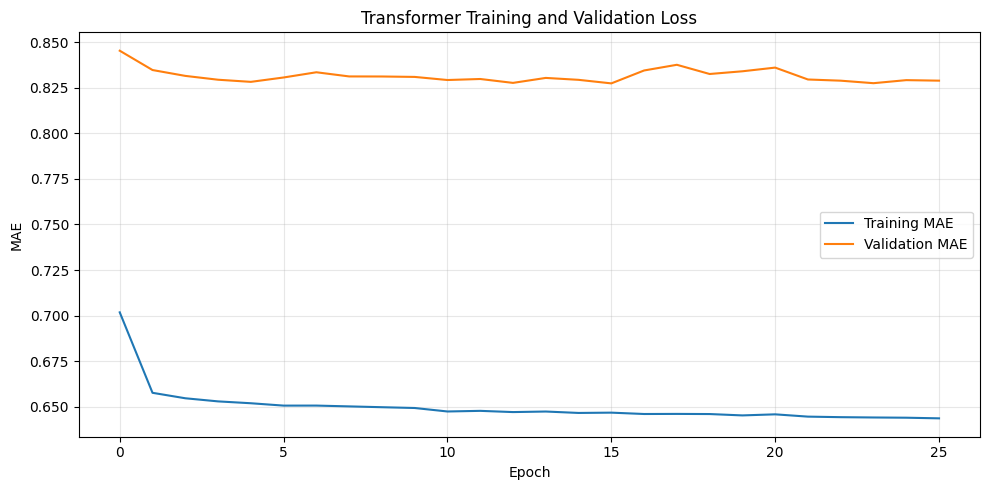

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/figures/transformer_training_history.png


In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_transformer.history[
        "loss"
    ],
    label="Training MAE"
)

plt.plot(
    history_transformer.history[
        "val_loss"
    ],
    label="Validation MAE"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "Transformer Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

TRANSFORMER_HISTORY_PATH = os.path.join(
    FIGURES_DIR,
    "transformer_training_history.png"
)

plt.savefig(
    TRANSFORMER_HISTORY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    TRANSFORMER_HISTORY_PATH
)

Generate forecasts

In [ ]:
val_pred_transformer = (
    transformer_model.predict(

        X_val,

        batch_size=256,

        verbose=0
    )
)

test_pred_transformer = (
    transformer_model.predict(

        X_test,

        batch_size=256,

        verbose=0
    )
)

# Retail demand cannot be negative

val_pred_transformer = np.clip(
    val_pred_transformer,
    0,
    None
)

test_pred_transformer = np.clip(
    test_pred_transformer,
    0,
    None
)

print(
    "Validation prediction:",
    val_pred_transformer.shape
)

print(
    "Test prediction:",
    test_pred_transformer.shape
)

Validation prediction: (300, 28)
Test prediction: (300, 28)


Define evaluation metrics

In [ ]:
def forecast_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    # -----------------------
    # MAE
    # -----------------------

    mae = np.mean(
        np.abs(
            y_true -
            y_pred
        )
    )

    # -----------------------
    # RMSE
    # -----------------------

    rmse = np.sqrt(
        np.mean(
            (
                y_true -
                y_pred
            ) ** 2
        )
    )

    # -----------------------
    # WAPE
    # -----------------------

    wape_denominator = np.sum(
        np.abs(
            y_true
        )
    )

    if wape_denominator > 0:

        wape = (

            np.sum(
                np.abs(
                    y_true -
                    y_pred
                )
            )

            /

            wape_denominator

        ) * 100

    else:

        wape = np.nan

    # -----------------------
    # sMAPE
    # -----------------------

    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_numerator = (
        2 *
        np.abs(
            y_true -
            y_pred
        )
    )

    smape_values = np.divide(

        smape_numerator,

        smape_denominator,

        out=np.zeros_like(
            smape_numerator,
            dtype=np.float64
        ),

        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_values
        ) * 100
    )

    return {

        "MAE":
            float(mae),

        "RMSE":
            float(rmse),

        "WAPE":
            float(wape),

        "sMAPE":
            float(smape)
    }

Evaluate Transformer

In [ ]:
transformer_val_metrics = (
    forecast_metrics(

        y_val,

        val_pred_transformer
    )
)

transformer_test_metrics = (
    forecast_metrics(

        y_test,

        test_pred_transformer
    )
)

print("=" * 65)
print("TRANSFORMER FORECASTING RESULTS")
print("=" * 65)

print("\nVALIDATION")
print("-" * 30)

for metric, value in (
    transformer_val_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )

print("\nTEST")
print("-" * 30)

for metric, value in (
    transformer_test_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )

TRANSFORMER FORECASTING RESULTS

VALIDATION
------------------------------
MAE     : 0.8274
RMSE    : 1.8336
WAPE    : 70.2392
sMAPE   : 134.3747

TEST
------------------------------
MAE     : 0.8384
RMSE    : 1.7694
WAPE    : 70.6655
sMAPE   : 133.3020


Save Transformer model

In [ ]:
TRANSFORMER_MODEL_PATH = os.path.join(
    TRANSFORMER_MODEL_DIR,
    "transformer_28day_forecaster.keras"
)

transformer_model.save(
    TRANSFORMER_MODEL_PATH
)

print(
    "Transformer model saved:"
)

print(
    TRANSFORMER_MODEL_PATH
)

Transformer model saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/transformer/transformer_28day_forecaster.keras


Save validation/test metrics

In [ ]:
transformer_metrics_df = pd.DataFrame([

    {
        "Dataset":
            "Validation",

        "Model":
            "Transformer",

        **transformer_val_metrics
    },

    {
        "Dataset":
            "Test",

        "Model":
            "Transformer",

        **transformer_test_metrics
    }

])

display(
    transformer_metrics_df.round(4)
)

TRANSFORMER_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "transformer_metrics.csv"
)

transformer_metrics_df.to_csv(
    TRANSFORMER_METRICS_PATH,
    index=False
)

print(
    "Saved:",
    TRANSFORMER_METRICS_PATH
)

,Dataset,Model,MAE,RMSE,WAPE,sMAPE
0,Validation,Transformer,0.8274,1.8336,70.2392,134.3747
1,Test,Transformer,0.8384,1.7694,70.6655,133.3020


Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/transformer_metrics.csv


Recover test metadata

In [ ]:
SUPERVISED_TEST_PATH = os.path.join(
    PROCESSED_DIR,
    "supervised",
    "test_supervised_28d.parquet"
)

test_supervised = pd.read_parquet(
    SUPERVISED_TEST_PATH
)

test_supervised["date"] = pd.to_datetime(
    test_supervised["date"]
)

print(
    "Test rows:",
    len(test_supervised)
)

print(
    "Transformer predictions:",
    len(test_pred_transformer)
)

Test rows: 300
Transformer predictions: 300


In [ ]:
if len(test_supervised) != len(
    test_pred_transformer
):

    raise ValueError(
        "Test metadata and Transformer "
        "prediction counts do not match."
    )

print(
    "Test metadata alignment verified."
)

Test metadata alignment verified.


Save Transformer test predictions

In [ ]:
prediction_records = []

for i in range(
    len(test_pred_transformer)
):

    series_key = str(
        test_supervised.iloc[i][
            "series_key"
        ]
    )

    origin_date = (
        test_supervised.iloc[i][
            "date"
        ]
    )

    for h in range(
        HORIZON
    ):

        prediction_records.append({

            "series_id":
                series_key,

            "origin_date":
                origin_date,

            "forecast_day":
                h + 1,

            "actual":
                float(
                    y_test[
                        i,
                        h
                    ]
                ),

            "prediction":
                float(
                    test_pred_transformer[
                        i,
                        h
                    ]
                ),

            "model":
                "Transformer"
        })


transformer_predictions_df = (
    pd.DataFrame(
        prediction_records
    )
)

display(
    transformer_predictions_df.head()
)

,series_id,origin_date,forecast_day,actual,prediction,model
0,FOODS_1_005_TX_3,2016-04-24,1,1.0,0.706403,Transformer
1,FOODS_1_005_TX_3,2016-04-24,2,0.0,0.725371,Transformer
2,FOODS_1_005_TX_3,2016-04-24,3,4.0,0.828740,Transformer
3,FOODS_1_005_TX_3,2016-04-24,4,1.0,1.029824,Transformer
4,FOODS_1_005_TX_3,2016-04-24,5,1.0,0.943138,Transformer


In [ ]:
TRANSFORMER_PREDICTIONS_PATH = os.path.join(
    PREDICTIONS_DIR,
    "transformer_test_predictions.csv"
)

transformer_predictions_df.to_csv(
    TRANSFORMER_PREDICTIONS_PATH,
    index=False
)

print(
    "Saved:",
    TRANSFORMER_PREDICTIONS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/predictions/transformer_test_predictions.csv


Calculate horizon-wise errors

In [ ]:
transformer_horizon_mae = np.mean(

    np.abs(
        y_test -
        test_pred_transformer
    ),

    axis=0
)

transformer_horizon_rmse = np.sqrt(

    np.mean(

        (
            y_test -
            test_pred_transformer
        ) ** 2,

        axis=0
    )
)

transformer_horizon_df = pd.DataFrame({

    "Forecast_Day":
        np.arange(
            1,
            HORIZON + 1
        ),

    "Transformer_MAE":
        transformer_horizon_mae,

    "Transformer_RMSE":
        transformer_horizon_rmse
})

display(
    transformer_horizon_df.round(4)
)

,Forecast_Day,Transformer_MAE,Transformer_RMSE
0,1,0.7206,1.5071
1,2,0.7807,1.5109
2,3,0.7511,1.6212
3,4,0.7397,1.8649
4,5,0.7283,1.3062
5,6,0.8494,2.2353
6,7,1.0014,2.0623
7,8,0.7660,1.5217
8,9,0.8316,1.6904
9,10,0.6656,1.2975


Save horizon-wise metrics

In [ ]:
TRANSFORMER_HORIZON_PATH = os.path.join(
    METRICS_DIR,
    "transformer_horizon_metrics.csv"
)

transformer_horizon_df.to_csv(
    TRANSFORMER_HORIZON_PATH,
    index=False
)

print(
    "Saved:",
    TRANSFORMER_HORIZON_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/transformer_horizon_metrics.csv


Plot Transformer horizon errors

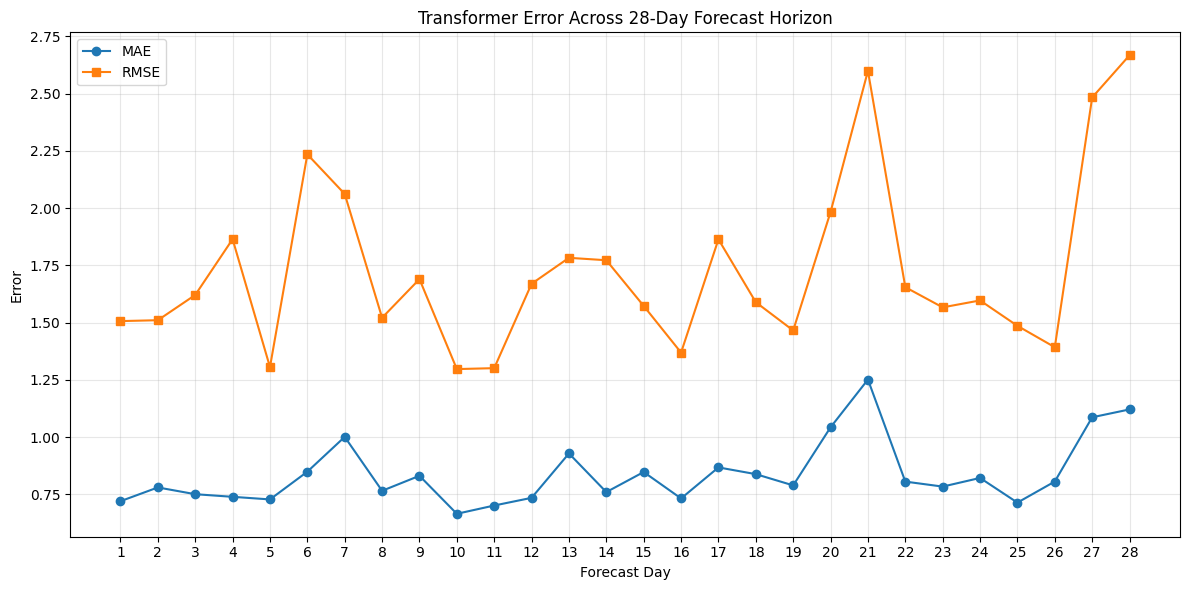

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(

    transformer_horizon_df[
        "Forecast_Day"
    ],

    transformer_horizon_df[
        "Transformer_MAE"
    ],

    marker="o",

    label="MAE"
)

plt.plot(

    transformer_horizon_df[
        "Forecast_Day"
    ],

    transformer_horizon_df[
        "Transformer_RMSE"
    ],

    marker="s",

    label="RMSE"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "Error"
)

plt.title(
    "Transformer Error Across 28-Day Forecast Horizon"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

TRANSFORMER_HORIZON_FIG = os.path.join(
    FIGURES_DIR,
    "transformer_horizon_error.png"
)

plt.savefig(
    TRANSFORMER_HORIZON_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Actual vs predicted demand

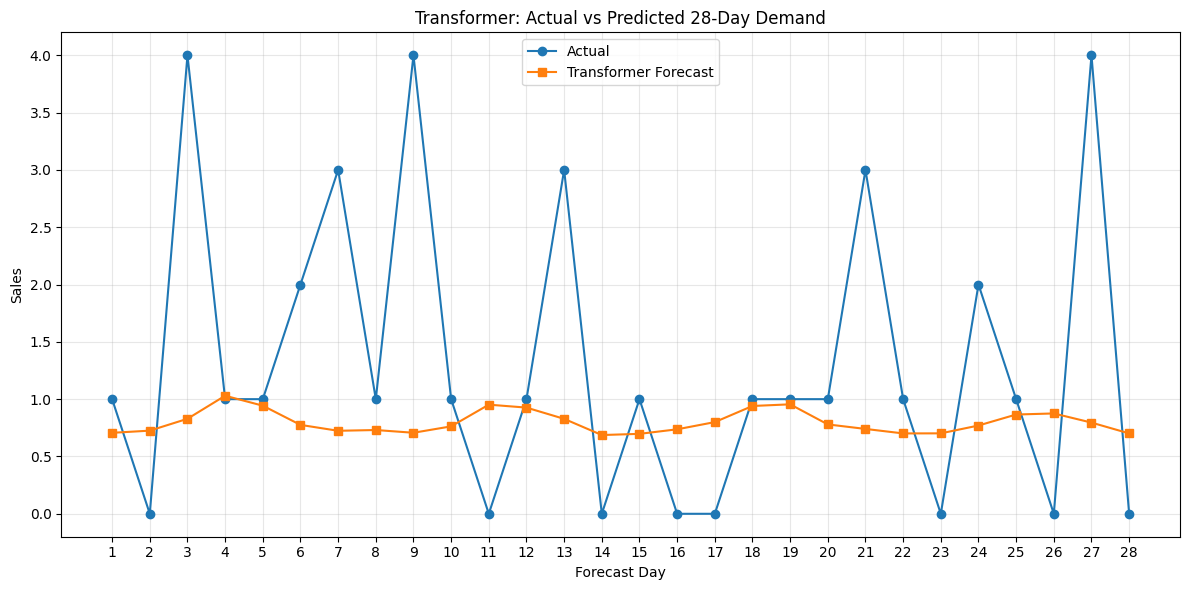

In [ ]:
SAMPLE_INDEX = 0

days = np.arange(
    1,
    HORIZON + 1
)

plt.figure(
    figsize=(12, 6)
)

plt.plot(

    days,

    y_test[
        SAMPLE_INDEX
    ],

    marker="o",

    label="Actual"
)

plt.plot(

    days,

    test_pred_transformer[
        SAMPLE_INDEX
    ],

    marker="s",

    label="Transformer Forecast"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "Sales"
)

plt.title(
    "Transformer: Actual vs Predicted 28-Day Demand"
)

plt.xticks(
    days
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

TRANSFORMER_FORECAST_FIG = os.path.join(
    FIGURES_DIR,
    "transformer_actual_vs_predicted.png"
)

plt.savefig(
    TRANSFORMER_FORECAST_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Load Step 10 LSTM metrics

In [ ]:
LSTM_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "lstm_metrics.csv"
)

if os.path.exists(
    LSTM_METRICS_PATH
):

    lstm_metrics_df = pd.read_csv(
        LSTM_METRICS_PATH
    )

    display(
        lstm_metrics_df
    )

else:

    print(
        "LSTM metrics file not found."
    )

,Dataset,Model,MAE,RMSE,WAPE,sMAPE
0,Validation,LSTM,0.812708,1.743712,68.991911,129.301639
1,Test,LSTM,0.833191,1.789356,70.226800,127.885373


Create LSTM vs Transformer comparison

In [ ]:
sequence_comparison_rows = []

if os.path.exists(
    LSTM_METRICS_PATH
):

    lstm_test_row = (
        lstm_metrics_df[
            lstm_metrics_df[
                "Dataset"
            ] == "Test"
        ]
    )

    if len(lstm_test_row) > 0:

        row = lstm_test_row.iloc[0]

        sequence_comparison_rows.append({

            "Model":
                "LSTM",

            "MAE":
                row["MAE"],

            "RMSE":
                row["RMSE"],

            "WAPE":
                row["WAPE"],

            "sMAPE":
                row["sMAPE"]
        })


sequence_comparison_rows.append({

    "Model":
        "Transformer",

    "MAE":
        transformer_test_metrics[
            "MAE"
        ],

    "RMSE":
        transformer_test_metrics[
            "RMSE"
        ],

    "WAPE":
        transformer_test_metrics[
            "WAPE"
        ],

    "sMAPE":
        transformer_test_metrics[
            "sMAPE"
        ]
})


sequence_model_comparison = pd.DataFrame(
    sequence_comparison_rows
)

display(
    sequence_model_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,LSTM,0.8332,1.7894,70.2268,127.8854
1,Transformer,0.8384,1.7694,70.6655,133.3020


Save LSTM vs Transformer comparison

In [ ]:
SEQUENCE_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "lstm_transformer_comparison.csv"
)

sequence_model_comparison.to_csv(
    SEQUENCE_COMPARISON_PATH,
    index=False
)

print(
    "Saved:",
    SEQUENCE_COMPARISON_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/lstm_transformer_comparison.csv


Compare LSTM and Transformer across all 28 days

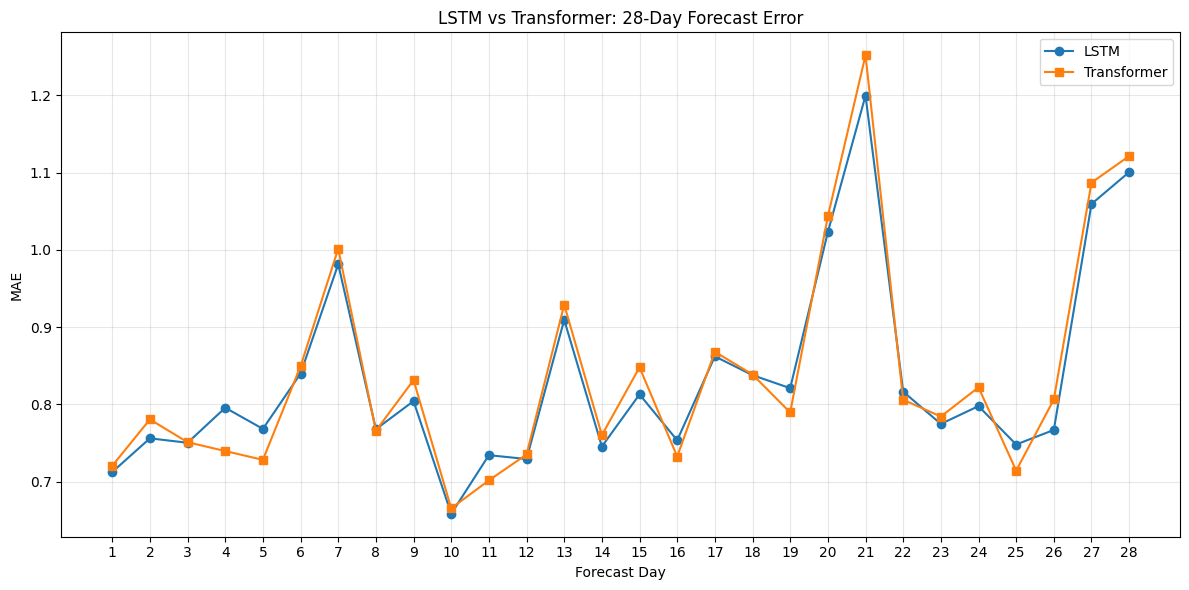

In [ ]:
LSTM_HORIZON_PATH = os.path.join(
    METRICS_DIR,
    "lstm_horizon_metrics.csv"
)

plt.figure(
    figsize=(12, 6)
)

if os.path.exists(
    LSTM_HORIZON_PATH
):

    lstm_horizon_df = pd.read_csv(
        LSTM_HORIZON_PATH
    )

    plt.plot(

        lstm_horizon_df[
            "Forecast_Day"
        ],

        lstm_horizon_df[
            "LSTM_MAE"
        ],

        marker="o",

        label="LSTM"
    )


plt.plot(

    transformer_horizon_df[
        "Forecast_Day"
    ],

    transformer_horizon_df[
        "Transformer_MAE"
    ],

    marker="s",

    label="Transformer"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "LSTM vs Transformer: 28-Day Forecast Error"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

LSTM_TRANSFORMER_FIG = os.path.join(
    FIGURES_DIR,
    "lstm_vs_transformer_horizon_mae.png"
)

plt.savefig(
    LSTM_TRANSFORMER_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Add Transformer to complete model comparison

In [ ]:
STEP10_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "models_with_lstm_comparison.csv"
)

if os.path.exists(
    STEP10_COMPARISON_PATH
):

    all_models_df = pd.read_csv(
        STEP10_COMPARISON_PATH
    )

else:

    REPRESENTATION_PATH = os.path.join(
        METRICS_DIR,
        "representation_learning_model_comparison.csv"
    )

    all_models_df = pd.read_csv(
        REPRESENTATION_PATH
    )

In [ ]:
transformer_result = pd.DataFrame([{

    "Model":
        "Transformer",

    "MAE":
        transformer_test_metrics[
            "MAE"
        ],

    "RMSE":
        transformer_test_metrics[
            "RMSE"
        ],

    "WAPE":
        transformer_test_metrics[
            "WAPE"
        ],

    "sMAPE":
        transformer_test_metrics[
            "sMAPE"
        ]
}])

In [ ]:
all_models_df = (
    all_models_df[
        all_models_df[
            "Model"
        ] != "Transformer"
    ]
    .copy()
)

step11_model_comparison = pd.concat(
    [
        all_models_df,
        transformer_result
    ],
    ignore_index=True
)

display(
    step11_model_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854
7,Transformer,0.8384,1.7694,70.6655,133.3020


Save complete model comparison

In [ ]:
STEP11_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "models_with_transformer_comparison.csv"
)

step11_model_comparison.to_csv(
    STEP11_COMPARISON_PATH,
    index=False
)

print(
    "Saved:",
    STEP11_COMPARISON_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/models_with_transformer_comparison.csv


Create model-comparison figure

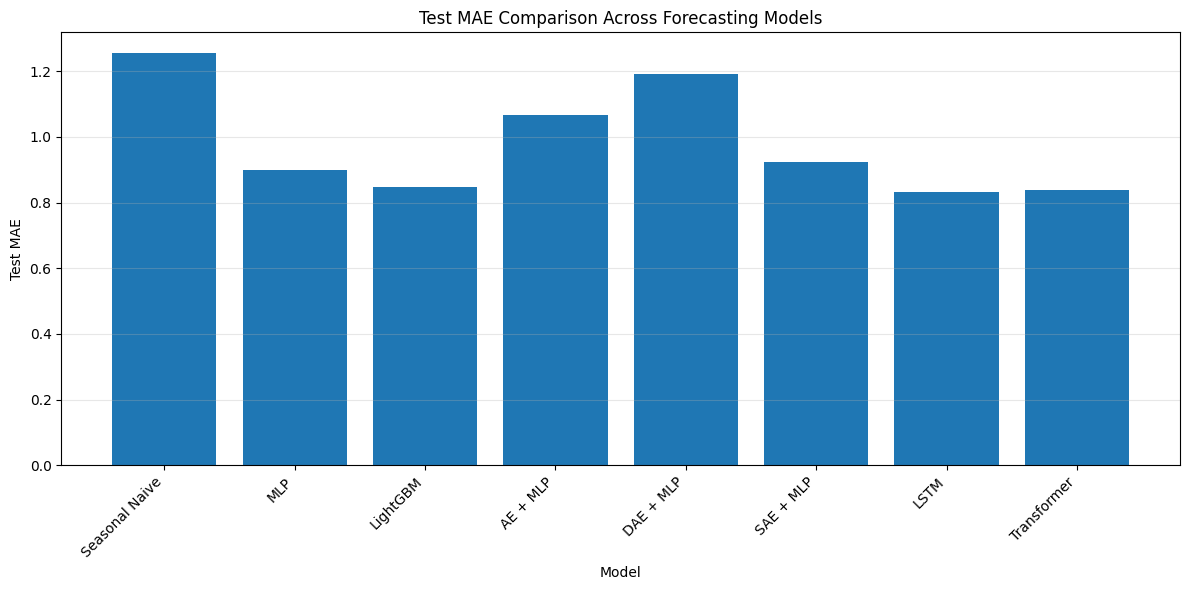

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.bar(
    step11_model_comparison[
        "Model"
    ],
    step11_model_comparison[
        "MAE"
    ]
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Test MAE"
)

plt.title(
    "Test MAE Comparison Across Forecasting Models"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

MODEL_COMPARISON_FIG = os.path.join(
    FIGURES_DIR,
    "step11_all_models_mae_comparison.png"
)

plt.savefig(
    MODEL_COMPARISON_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Save Transformer configuration

In [ ]:
transformer_config = {

    "model":
        "Transformer",

    "sequence_length":
        int(SEQUENCE_LENGTH),

    "input_features":
        int(INPUT_FEATURES),

    "forecast_horizon":
        int(HORIZON),

    "d_model":
        D_MODEL,

    "num_heads":
        NUM_HEADS,

    "feed_forward_dimension":
        FF_DIM,

    "transformer_blocks":
        NUM_TRANSFORMER_BLOCKS,

    "dropout_rate":
        DROPOUT_RATE,

    "input_projection":
        D_MODEL,

    "pooling":
        "GlobalAveragePooling1D",

    "forecast_head": [
        64,
        32,
        HORIZON
    ],

    "loss":
        "MAE",

    "optimizer":
        "Adam",

    "learning_rate":
        0.001
}

TRANSFORMER_CONFIG_PATH = os.path.join(
    TRANSFORMER_MODEL_DIR,
    "transformer_config.json"
)

with open(
    TRANSFORMER_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        transformer_config,
        f,
        indent=4
    )

print(
    "Configuration saved:"
)

print(
    TRANSFORMER_CONFIG_PATH
)

Configuration saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/transformer/transformer_config.json


Reload saved Transformer model test

In [ ]:
reloaded_transformer = tf.keras.models.load_model(

    TRANSFORMER_MODEL_PATH,

    custom_objects={
        "PositionalEmbedding":
            PositionalEmbedding
    }
)

reload_prediction = (
    reloaded_transformer.predict(
        X_test[:5],
        verbose=0
    )
)

print(
    "Reloaded model output:",
    reload_prediction.shape
)

print(
    "Reload test successful."
)

Reloaded model output: (5, 28)
Reload test successful.


Optional per-series error analysis

In [ ]:
series_mae = np.mean(

    np.abs(
        y_test -
        test_pred_transformer
    ),

    axis=1
)

series_rmse = np.sqrt(

    np.mean(

        (
            y_test -
            test_pred_transformer
        ) ** 2,

        axis=1
    )
)

transformer_series_metrics = pd.DataFrame({

    "series_key":
        test_supervised[
            "series_key"
        ]
        .astype(str)
        .values,

    "origin_date":
        test_supervised[
            "date"
        ]
        .values,

    "MAE":
        series_mae,

    "RMSE":
        series_rmse
})

display(
    transformer_series_metrics.head()
)

,series_key,origin_date,MAE,RMSE
0,FOODS_1_005_TX_3,2016-04-24,0.965396,1.395148
1,FOODS_1_049_TX_2,2016-04-24,0.142919,0.462895
2,FOODS_1_079_CA_2,2016-04-24,0.071504,0.377964
3,FOODS_1_079_CA_4,2016-04-24,0.392888,0.731887
4,FOODS_1_083_WI_2,2016-04-24,1.893944,2.639585


In [ ]:
TRANSFORMER_SERIES_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "transformer_series_metrics.csv"
)

transformer_series_metrics.to_csv(
    TRANSFORMER_SERIES_METRICS_PATH,
    index=False
)

print(
    "Saved:",
    TRANSFORMER_SERIES_METRICS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/transformer_series_metrics.csv


Final Step 11 verification

In [ ]:
print("=" * 82)
print("STEP 11 - TRANSFORMER FORECASTING FINAL VERIFICATION")
print("=" * 82)

print("\n1. TRANSFORMER INPUT")
print("-" * 48)

print(
    "Sequence length       :",
    SEQUENCE_LENGTH
)

print(
    "Features per timestep :",
    INPUT_FEATURES
)

print(
    "Forecast horizon      :",
    HORIZON
)


print("\n2. MODEL ARCHITECTURE")
print("-" * 48)

print(
    "D_MODEL               :",
    D_MODEL
)

print(
    "Attention heads       :",
    NUM_HEADS
)

print(
    "FF dimension          :",
    FF_DIM
)

print(
    "Transformer blocks    :",
    NUM_TRANSFORMER_BLOCKS
)


print("\n3. DATA SHAPES")
print("-" * 48)

print(
    "Train:",
    X_train.shape,
    "->",
    y_train.shape
)

print(
    "Validation:",
    X_val.shape,
    "->",
    y_val.shape
)

print(
    "Test:",
    X_test.shape,
    "->",
    y_test.shape
)


print("\n4. TRANSFORMER TEST METRICS")
print("-" * 48)

for metric, value in (
    transformer_test_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )


print("\n5. SAVED FILES")
print("-" * 48)

files_to_check = {

    "Best Transformer":
        BEST_TRANSFORMER_PATH,

    "Final Transformer":
        TRANSFORMER_MODEL_PATH,

    "Transformer metrics":
        TRANSFORMER_METRICS_PATH,

    "Transformer predictions":
        TRANSFORMER_PREDICTIONS_PATH,

    "Horizon metrics":
        TRANSFORMER_HORIZON_PATH,

    "Series metrics":
        TRANSFORMER_SERIES_METRICS_PATH,

    "LSTM/Transformer comparison":
        SEQUENCE_COMPARISON_PATH,

    "Complete comparison":
        STEP11_COMPARISON_PATH,

    "Transformer config":
        TRANSFORMER_CONFIG_PATH
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:31s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 82)

if all_saved:

    print(
        "STEP 11 COMPLETED SUCCESSFULLY"
    )

    print(
        "28-DAY HISTORY -> TRANSFORMER -> "
        "28-DAY DEMAND FORECAST"
    )

else:

    print(
        "STEP 11 INCOMPLETE - "
        "CHECK THE MISSING FILES ABOVE"
    )

print("=" * 82)

STEP 11 - TRANSFORMER FORECASTING FINAL VERIFICATION

1. TRANSFORMER INPUT
------------------------------------------------
Sequence length       : 28
Features per timestep : 1
Forecast horizon      : 28

2. MODEL ARCHITECTURE
------------------------------------------------
D_MODEL               : 32
Attention heads       : 4
FF dimension          : 64
Transformer blocks    : 2

3. DATA SHAPES
------------------------------------------------
Train: (79200, 28, 1) -> (79200, 28)
Validation: (300, 28, 1) -> (300, 28)
Test: (300, 28, 1) -> (300, 28)

4. TRANSFORMER TEST METRICS
------------------------------------------------
MAE     : 0.8384
RMSE    : 1.7694
WAPE    : 70.6655
sMAPE   : 133.3020

5. SAVED FILES
------------------------------------------------
Best Transformer               : FOUND
Final Transformer              : FOUND
Transformer metrics            : FOUND
Transformer predictions        : FOUND
Horizon metrics                : FOUND
Series metrics                 : FOUN